In [7]:
# ==================== CELL 1: Setup & Merge manifest.csv with runs.csv ====================
import os
import random
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import imagehash
from IPython.display import Image as IPyImage, display

DATASET_DIR = "11106655_pallet_part00_phase20"
FIG_DIR = "report_figures"
os.makedirs(FIG_DIR, exist_ok=True)

manifest = pd.read_csv(os.path.join(DATASET_DIR, "manifest.csv"))
runs_path = os.path.join(DATASET_DIR, "generation", "runs.csv")
if not os.path.exists(runs_path):
    runs_path = os.path.join(DATASET_DIR, "pilot", "runs_pilot.csv")
runs = pd.read_csv(runs_path)

# Normalize filenames (strip directories and .json extension) for reliable matching
manifest["_join_key"] = manifest["source_json"].apply(lambda x: os.path.splitext(os.path.basename(str(x)))[0])
runs["_join_key"] = runs["export_file"].apply(lambda x: os.path.splitext(os.path.basename(str(x)))[0])

merge_cols = [
    "_join_key", "run_id", "mode", "surface_mode", "seed",
    "jitterRatio", "materialVariation",
    "alphaMin", "alphaMax", "alphaStep",
    "betaMin", "betaMax", "betaStep",
    "radiusFactorMin", "radiusFactorMax", "radiusFactorStep"
]

manifest = manifest.drop(columns=[c for c in merge_cols if c != "_join_key" and c in manifest.columns])
manifest = manifest.merge(runs[merge_cols], on="_join_key", how="left")

# Fallback: extract mode prefix (M1-M5) if any run filename differs slightly
manifest["mode"] = manifest["mode"].fillna(manifest["_join_key"].str.extract(r"^(M[1-5])", expand=False).str.upper())
manifest.drop(columns=["_join_key"], inplace=True)

manifest.to_csv(os.path.join(DATASET_DIR, "manifest.csv"), index=False)
print(f"Loaded and updated manifest.csv: {len(manifest)} images.")
print(f"Missing mode entries: {manifest['mode'].isna().sum()}")

Loaded and updated manifest.csv: 258 images.
Missing mode entries: 0


In [8]:
# ==================== CELL 2: Parse All Images, Bounding Boxes & Segmentation Polygons ====================
with open(os.path.join(DATASET_DIR, "data.yaml"), "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

resolutions = set()
instances_records = []
r10_errors = []
poly_box_diffs_px = []

for _, row in manifest.iterrows():
    img_name = row["image"]
    stem = os.path.splitext(img_name)[0]
    img_path = os.path.join(DATASET_DIR, "images", img_name)
    box_path = os.path.join(DATASET_DIR, "labels", f"{stem}.txt")
    seg_path = os.path.join(DATASET_DIR, "labels_seg", f"{stem}.txt")

    if not os.path.exists(img_path):
        r10_errors.append(f"Missing image file: {img_name}")
        continue

    with Image.open(img_path) as im:
        w_px, h_px = im.size
        resolutions.add((w_px, h_px))

    if not os.path.exists(box_path) or not os.path.exists(seg_path):
        r10_errors.append(f"Missing label file(s) for: {stem}")
        continue

    with open(box_path, "r", encoding="utf-8") as fb, open(seg_path, "r", encoding="utf-8") as fs:
        box_lines = [l.strip() for l in fb if l.strip()]
        seg_lines = [l.strip() for l in fs if l.strip()]

    if len(box_lines) != len(seg_lines) or not (1 <= len(box_lines) <= 5):
        r10_errors.append(f"Instance count mismatch or out of range [1,5] in {stem}: box={len(box_lines)}, seg={len(seg_lines)}")

    for b_line, s_line in zip(box_lines, seg_lines):
        b_parts = list(map(float, b_line.split()))
        s_parts = list(map(float, s_line.split()))

        if len(b_parts) != 5:
            r10_errors.append(f"Invalid box column count in {stem}")
            continue
        if len(s_parts) < 7 or (len(s_parts) - 1) % 2 != 0:
            r10_errors.append(f"Invalid polygon vertex count in {stem}")
            continue

        cls_b, cx, cy, bw, bh = int(b_parts[0]), b_parts[1], b_parts[2], b_parts[3], b_parts[4]
        cls_s = int(s_parts[0])
        pts = np.array(s_parts[1:], dtype=float).reshape(-1, 2)

        if cls_b != 0 or cls_s != 0:
            r10_errors.append(f"Non-zero class ID found in {stem}")
        if not (0.0 <= cx <= 1.0 and 0.0 <= cy <= 1.0 and 0.0 < bw <= 1.0 and 0.0 < bh <= 1.0):
            r10_errors.append(f"Box coordinates out of [0, 1] in {stem}")
        if len(pts) < 3 or np.any(pts < 0.0) or np.any(pts > 1.0):
            r10_errors.append(f"Polygon vertices invalid or out of [0, 1] in {stem}")

        # Compare bounding box vs. polygon extent in pixels
        bx1, by1 = (cx - bw / 2.0) * w_px, (cy - bh / 2.0) * h_px
        bx2, by2 = (cx + bw / 2.0) * w_px, (cy + bh / 2.0) * h_px
        px1, py1 = pts[:, 0].min() * w_px, pts[:, 1].min() * h_px
        px2, py2 = pts[:, 0].max() * w_px, pts[:, 1].max() * h_px
        max_diff = max(abs(bx1 - px1), abs(by1 - py1), abs(bx2 - px2), abs(by2 - py2))
        poly_box_diffs_px.append(max_diff)

        # Truncation flag: box edge within 2.0 px of image border
        is_truncated = (bx1 <= 2.0) or (by1 <= 2.0) or (bx2 >= w_px - 2.0) or (by2 >= h_px - 2.0)

        instances_records.append({
            "image": img_name,
            "mode": row["mode"],
            "w_px": w_px,
            "h_px": h_px,
            "cx": cx,
            "cy": cy,
            "bw": bw,
            "bh": bh,
            "area_pct": bw * bh * 100.0,
            "short_side_px": min(bw * w_px, bh * h_px),
            "truncated": is_truncated,
            "poly_box_diff_px": max_diff
        })

df_inst = pd.DataFrame(instances_records)
print(f"Parsing complete: {len(manifest)} images, {len(df_inst)} total instances.")

Parsing complete: 258 images, 376 total instances.


In [9]:
# ==================== CELL 3: R1 - Dataset Size and Class ====================
total_images = len(manifest)
num_classes = data_cfg.get("nc", -1)
class_names = data_cfg.get("names", [])
r1_pass = (total_images == 1000) and (num_classes == 1) and (len(class_names) == 1)

print("=== R1: Dataset Size and Class ===")
print(f"Target   : Exactly 1,000 images, 1 class (pallet_part00_phase20)")
print(f"Measured : {total_images} images, nc={num_classes}, names={class_names}")
print(f"Status   : {'PASS' if r1_pass else 'FAIL'}")

=== R1: Dataset Size and Class ===
Target   : Exactly 1,000 images, 1 class (pallet_part00_phase20)
Measured : 258 images, nc=1, names={0: 'pallet_part00_phase20'}
Status   : FAIL


=== R2: Instances per Image ===
Target   : 1: 70%, 2: 10%, 3: 8%, 4: 6%, 5: 6% (±3% tolerance per bin)
  Bin 1:  206 images (79.84%, diff=+9.84%)
  Bin 2:   19 images ( 7.36%, diff=-2.64%)
  Bin 3:   10 images ( 3.88%, diff=-4.12%)
  Bin 4:   13 images ( 5.04%, diff=-0.96%)
  Bin 5:   10 images ( 3.88%, diff=-2.12%)
Images outside [1, 5] instances: 0
Status   : FAIL


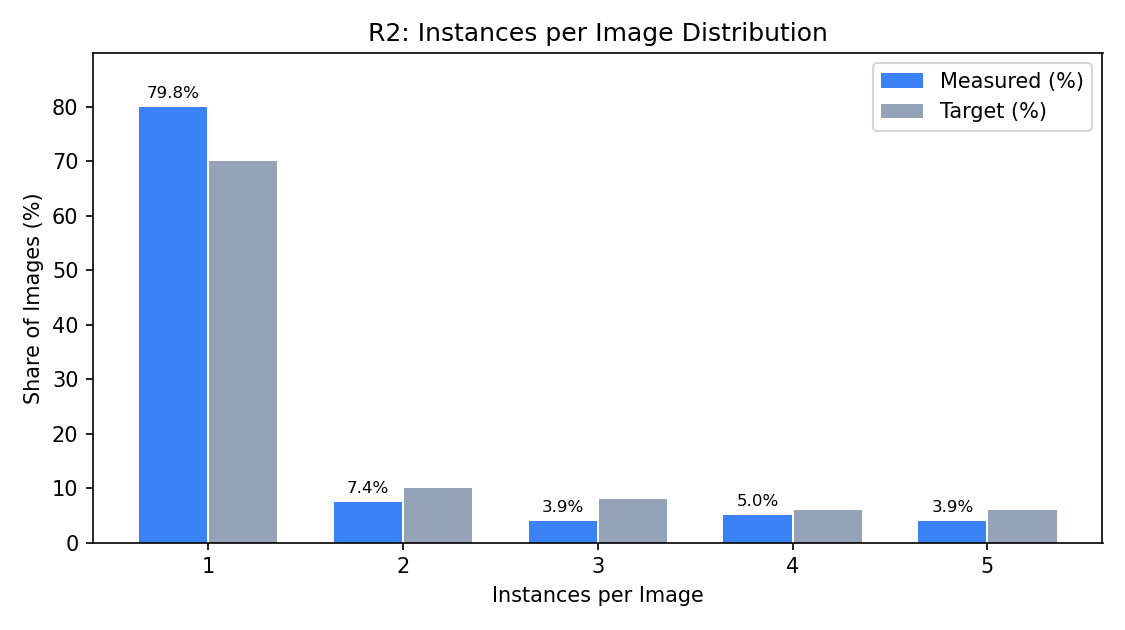

In [10]:
# ==================== CELL 4: R2 - Instances per Image ====================
inst_counts = manifest["n_instances"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
inst_shares = inst_counts / len(manifest) * 100.0
targets_r2 = [70.0, 10.0, 8.0, 6.0, 6.0]
invalid_inst_imgs = manifest[~manifest["n_instances"].isin([1, 2, 3, 4, 5])]

r2_bins_ok = all(abs(inst_shares.iloc[k] - targets_r2[k]) <= 3.0 for k in range(5))
r2_pass = r2_bins_ok and (len(invalid_inst_imgs) == 0)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(5)
bars_meas = ax.bar(x - 0.18, inst_shares, width=0.35, label="Measured (%)", color="#3B82F6")
bars_targ = ax.bar(x + 0.18, targets_r2, width=0.35, label="Target (%)", color="#94A3B8")

ax.set_xticks(x)
ax.set_xticklabels(["1", "2", "3", "4", "5"])
ax.set_title("R2: Instances per Image Distribution")
ax.set_xlabel("Instances per Image")
ax.set_ylabel("Share of Images (%)")
ax.set_ylim(0, max(max(inst_shares), 75) + 10)
ax.legend()

for bar in bars_meas:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
out_r2 = f"{FIG_DIR}/R2_instances_per_image.png"
plt.savefig(out_r2, dpi=150)
plt.close()

print("=== R2: Instances per Image ===")
print("Target   : 1: 70%, 2: 10%, 3: 8%, 4: 6%, 5: 6% (±3% tolerance per bin)")
for k in range(5):
    diff = inst_shares.iloc[k] - targets_r2[k]
    print(f"  Bin {k+1}: {inst_counts.iloc[k]:4d} images ({inst_shares.iloc[k]:5.2f}%, diff={diff:+5.2f}%)")
print(f"Images outside [1, 5] instances: {len(invalid_inst_imgs)}")
print(f"Status   : {'PASS' if r2_pass else 'FAIL'}")
display(IPyImage(filename=out_r2))

In [11]:
# ==================== CELL 5: R3 - Image Format and Resolution ====================
res_list = sorted(list(resolutions))
is_non_square = all(w != h for w, h in res_list)
r3_pass = (len(res_list) == 1) and is_non_square

print("=== R3: Image Format and Resolution ===")
print("Target   : Single uniform resolution across all images, Square Image unticked (W != H)")
print(f"Measured : {len(res_list)} unique resolution(s) -> {res_list}")
print(f"Status   : {'PASS' if r3_pass else 'FAIL'}")

=== R3: Image Format and Resolution ===
Target   : Single uniform resolution across all images, Square Image unticked (W != H)
Measured : 1 unique resolution(s) -> [(1920, 1080)]
Status   : PASS


=== R4: Generation-Mode Mix ===
Target   : M2 = 300–330 images (30%); M1, M3, M4, M5 >= 10% each
  M1:   40 images (15.50%)
  M2:   52 images (20.16%)
  M3:   60 images (23.26%)
  M4:   51 images (19.77%)
  M5:   55 images (21.32%)
Status   : FAIL


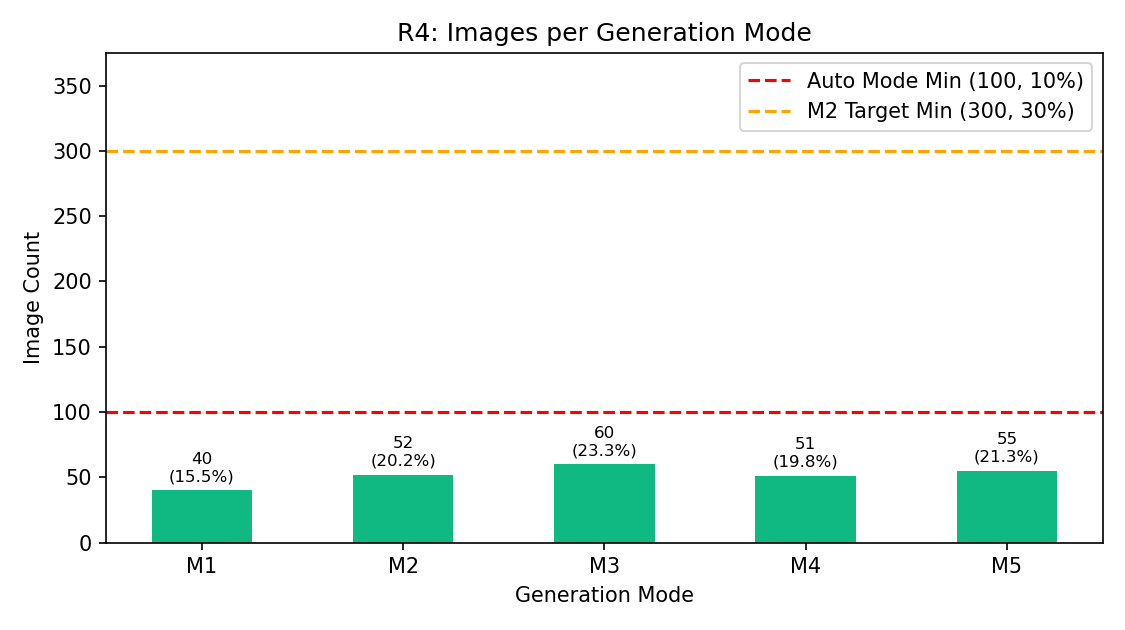

In [12]:
# ==================== CELL 6: R4 - Generation-Mode Mix ====================
modes_order = ["M1", "M2", "M3", "M4", "M5"]
mode_counts = manifest["mode"].value_counts().reindex(modes_order, fill_value=0)
mode_shares = mode_counts / len(manifest) * 100.0

m2_ok = 300 <= mode_counts["M2"] <= 330
auto_ok = all(mode_shares[m] >= 10.0 for m in ["M1", "M3", "M4", "M5"])
r4_pass = m2_ok and auto_ok

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars_mode = ax.bar(mode_counts.index, mode_counts.values, color="#10B981", width=0.5)
ax.axhline(100, color="red", linestyle="--", label="Auto Mode Min (100, 10%)")
ax.axhline(300, color="orange", linestyle="--", label="M2 Target Min (300, 30%)")
ax.set_title("R4: Images per Generation Mode")
ax.set_xlabel("Generation Mode")
ax.set_ylabel("Image Count")
ax.set_ylim(0, max(max(mode_counts.values), 330) + 45)
ax.legend()

for bar in bars_mode:
    h = int(bar.get_height())
    pct = h / len(manifest) * 100.0
    ax.annotate(f"{h}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
out_r4 = f"{FIG_DIR}/R4_generation_modes.png"
plt.savefig(out_r4, dpi=150)
plt.close()

print("=== R4: Generation-Mode Mix ===")
print("Target   : M2 = 300–330 images (30%); M1, M3, M4, M5 >= 10% each")
for m in modes_order:
    print(f"  {m}: {mode_counts[m]:4d} images ({mode_shares[m]:5.2f}%)")
print(f"Status   : {'PASS' if r4_pass else 'FAIL'}")
display(IPyImage(filename=out_r4))

=== R5: Scale Ladder ===
Target   : Small (<1%): 30%, Medium (1–10%): 40%, Large (>10%): 30% (±5% tolerance)
  Small  (< 1%)  :  160 instances (42.55%, diff=+12.55%)
  Medium (1–10%) :   67 instances (17.82%, diff=-22.18%)
  Large  (> 10%) :  149 instances (39.63%, diff=+9.63%)
Status   : FAIL


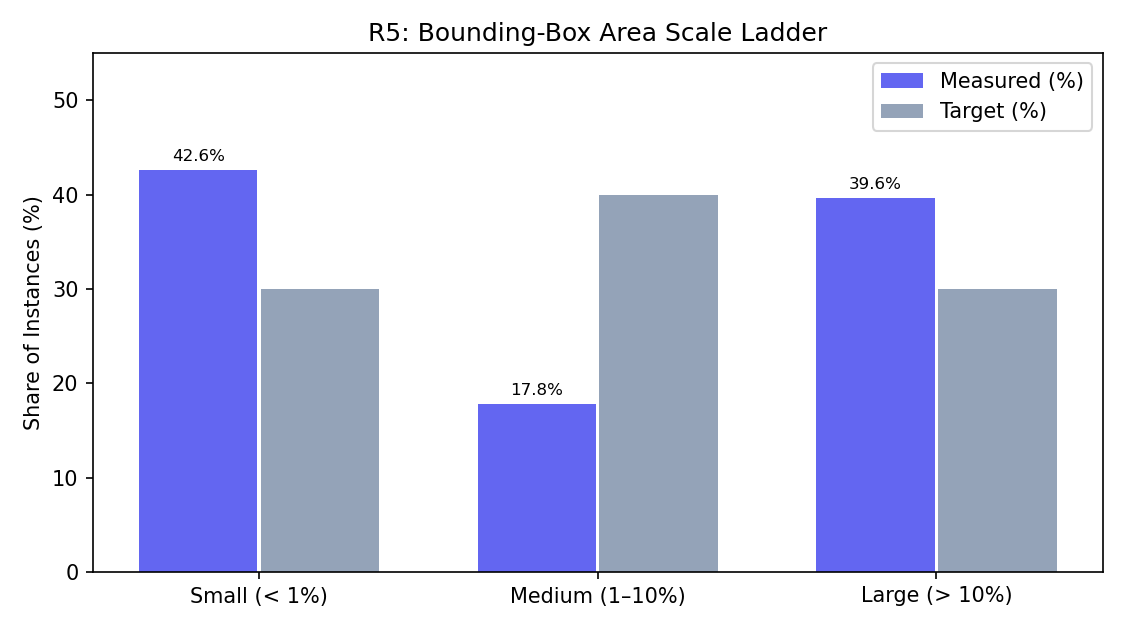

In [13]:
# ==================== CELL 7: R5 - Scale Ladder (Box Area Distribution) ====================
small_cnt = (df_inst["area_pct"] < 1.0).sum()
med_cnt = ((df_inst["area_pct"] >= 1.0) & (df_inst["area_pct"] <= 10.0)).sum()
large_cnt = (df_inst["area_pct"] > 10.0).sum()

n_total_inst = len(df_inst)
r5_meas = [small_cnt / n_total_inst * 100.0, med_cnt / n_total_inst * 100.0, large_cnt / n_total_inst * 100.0]
r5_targ = [30.0, 40.0, 30.0]
r5_pass = all(abs(r5_meas[k] - r5_targ[k]) <= 5.0 for k in range(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
xb = np.arange(3)
b_meas = ax.bar(xb - 0.18, r5_meas, width=0.35, label="Measured (%)", color="#6366F1")
b_targ = ax.bar(xb + 0.18, r5_targ, width=0.35, label="Target (%)", color="#94A3B8")

ax.set_xticks(xb)
ax.set_xticklabels(["Small (< 1%)", "Medium (1–10%)", "Large (> 10%)"])
ax.set_title("R5: Bounding-Box Area Scale Ladder")
ax.set_ylabel("Share of Instances (%)")
ax.set_ylim(0, max(max(r5_meas), 45) + 10)
ax.legend()

for bar in b_meas:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
out_r5 = f"{FIG_DIR}/R5_scale_ladder.png"
plt.savefig(out_r5, dpi=150)
plt.close()

print("=== R5: Scale Ladder ===")
print("Target   : Small (<1%): 30%, Medium (1–10%): 40%, Large (>10%): 30% (±5% tolerance)")
print(f"  Small  (< 1%)  : {small_cnt:4d} instances ({r5_meas[0]:5.2f}%, diff={r5_meas[0]-30.0:+5.2f}%)")
print(f"  Medium (1–10%) : {med_cnt:4d} instances ({r5_meas[1]:5.2f}%, diff={r5_meas[1]-40.0:+5.2f}%)")
print(f"  Large  (> 10%) : {large_cnt:4d} instances ({r5_meas[2]:5.2f}%, diff={r5_meas[2]-30.0:+5.2f}%)")
print(f"Status   : {'PASS' if r5_pass else 'FAIL'}")
display(IPyImage(filename=out_r5))

=== R6: Viewpoint Coverage ===
Target   : All 24/24 cells covered (8 azimuth sectors x 3 elevation bands)
Measured : 24/24 cells covered
Status   : PASS


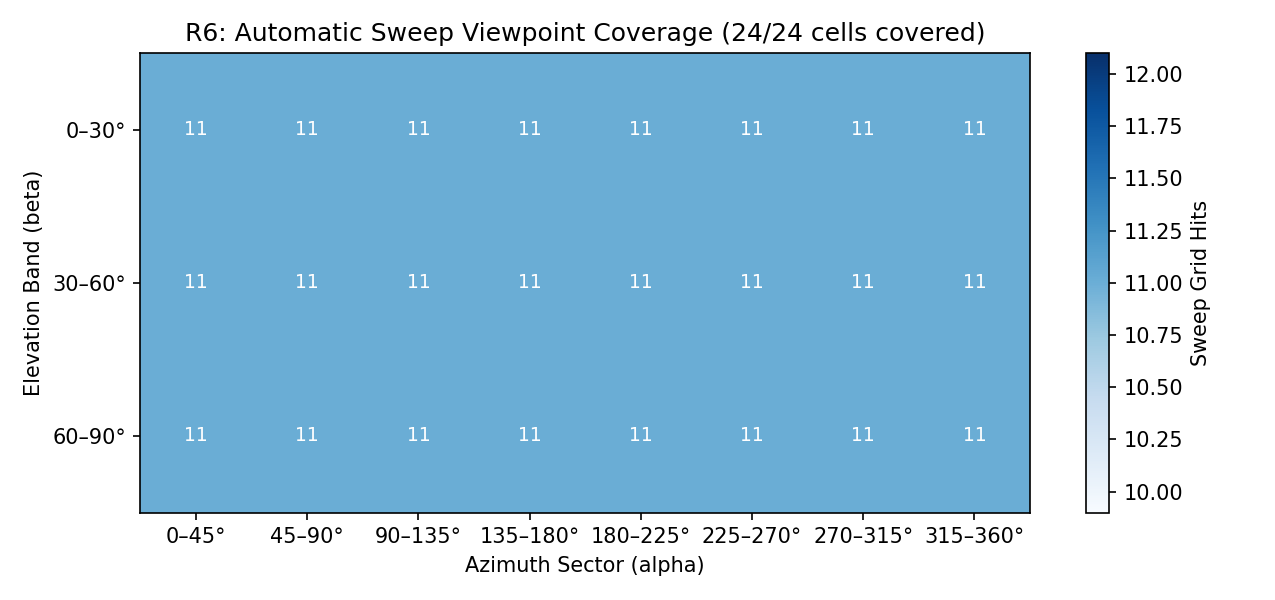

In [14]:
# ==================== CELL 8: R6 - Viewpoint Coverage (Azimuth x Elevation) ====================
auto_runs = runs[runs["mode"].isin(["M1", "M3", "M4", "M5"])].dropna(
    subset=["alphaMin", "alphaMax", "alphaStep", "betaMin", "betaMax", "betaStep"]
)

grid_r6 = np.zeros((3, 8), dtype=int)
for _, r in auto_runs.iterrows():
    alphas = np.arange(float(r["alphaMin"]), float(r["alphaMax"]) + 1e-5, float(r["alphaStep"])) % 360.0
    betas = np.arange(float(r["betaMin"]), float(r["betaMax"]) + 1e-5, float(r["betaStep"]))
    for a in alphas:
        for b in betas:
            if 0.0 <= b < 90.0:
                az_idx = int(a // 45.0)
                el_idx = int(b // 30.0)
                grid_r6[el_idx, az_idx] += 1

covered_cells = int((grid_r6 > 0).sum())
r6_pass = (covered_cells == 24)

fig, ax = plt.subplots(figsize=(8.5, 4.0))
im_r6 = ax.imshow(grid_r6, cmap="Blues", aspect="auto")
ax.set_xticks(range(8))
ax.set_xticklabels([f"{i*45}–{(i+1)*45}°" for i in range(8)])
ax.set_yticks(range(3))
ax.set_yticklabels(["0–30°", "30–60°", "60–90°"])
ax.set_xlabel("Azimuth Sector (alpha)")
ax.set_ylabel("Elevation Band (beta)")
ax.set_title(f"R6: Automatic Sweep Viewpoint Coverage ({covered_cells}/24 cells covered)")

for i in range(3):
    for j in range(8):
        ax.text(j, i, str(grid_r6[i, j]), ha="center", va="center",
                color="white" if grid_r6[i, j] > grid_r6.max() * 0.6 else "black", fontsize=9)

plt.colorbar(im_r6, ax=ax, label="Sweep Grid Hits")
plt.tight_layout()
out_r6 = f"{FIG_DIR}/R6_viewpoint_coverage.png"
plt.savefig(out_r6, dpi=150)
plt.close()

print("=== R6: Viewpoint Coverage ===")
print("Target   : All 24/24 cells covered (8 azimuth sectors x 3 elevation bands)")
print(f"Measured : {covered_cells}/24 cells covered")
print(f"Status   : {'PASS' if r6_pass else 'FAIL'}")
display(IPyImage(filename=out_r6))

=== R7: Position in Frame ===
Target   : Each outer cell >= 3.0% of instances; centre cell <= 50.0%
Measured : Min outer cell = 2.13%, Centre cell = 62.23%
Status   : FAIL


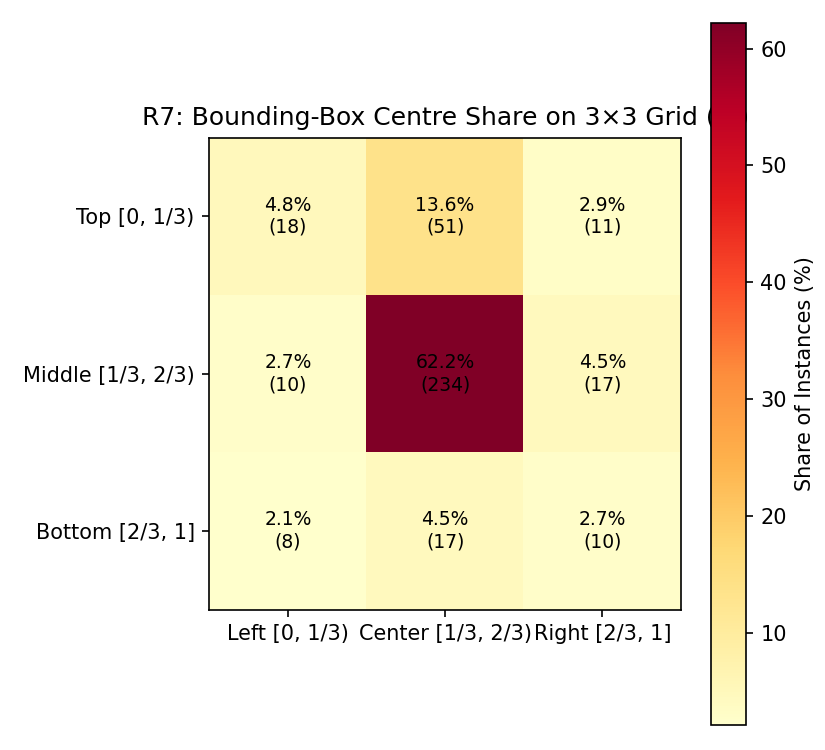

In [15]:
# ==================== CELL 9: R7 - Position in Frame (3x3 Grid Heatmap) ====================
grid_r7 = np.zeros((3, 3), dtype=int)
for _, r in df_inst.iterrows():
    col = min(int(r["cx"] * 3.0), 2)
    row = min(int(r["cy"] * 3.0), 2)
    grid_r7[row, col] += 1

grid_r7_pct = grid_r7 / len(df_inst) * 100.0
outer_cells_pct = [grid_r7_pct[i, j] for i in range(3) for j in range(3) if not (i == 1 and j == 1)]
min_outer_pct = min(outer_cells_pct)
centre_pct = grid_r7_pct[1, 1]
r7_pass = (min_outer_pct >= 3.0) and (centre_pct <= 50.0)

fig, ax = plt.subplots(figsize=(5.5, 5.0))
im_r7 = ax.imshow(grid_r7_pct, cmap="YlOrRd")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Left [0, 1/3)", "Center [1/3, 2/3)", "Right [2/3, 1]"])
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Top [0, 1/3)", "Middle [1/3, 2/3)", "Bottom [2/3, 1]"])
ax.set_title("R7: Bounding-Box Centre Share on 3×3 Grid (%)")

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{grid_r7_pct[i, j]:.1f}%\n({grid_r7[i, j]})",
                ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im_r7, ax=ax, label="Share of Instances (%)")
plt.tight_layout()
out_r7 = f"{FIG_DIR}/R7_position_heatmap.png"
plt.savefig(out_r7, dpi=150)
plt.close()

print("=== R7: Position in Frame ===")
print("Target   : Each outer cell >= 3.0% of instances; centre cell <= 50.0%")
print(f"Measured : Min outer cell = {min_outer_pct:.2f}%, Centre cell = {centre_pct:.2f}%")
print(f"Status   : {'PASS' if r7_pass else 'FAIL'}")
display(IPyImage(filename=out_r7))

In [16]:
# ==================== CELL 10: R8 - Truncation Share ====================
trunc_count = int(df_inst["truncated"].sum())
trunc_rate = df_inst["truncated"].mean() * 100.0
r8_pass = 5.0 <= trunc_rate <= 15.0

print("=== R8: Truncation Share ===")
print("Target   : 5.0% to 15.0% of instances cut by the image border")
print(f"Measured : {trunc_count} / {len(df_inst)} instances ({trunc_rate:.2f}%)")
print(f"Status   : {'PASS' if r8_pass else 'FAIL'}")

=== R8: Truncation Share ===
Target   : 5.0% to 15.0% of instances cut by the image border
Measured : 18 / 376 instances (4.79%)
Status   : FAIL


In [17]:
# ==================== CELL 11: R9 - Minimum Bounding-Box Size ====================
min_short_px = float(df_inst["short_side_px"].min())
violations_r9 = int((df_inst["short_side_px"] < 16.0).sum())
r9_pass = (min_short_px >= 16.0) and (violations_r9 == 0)

print("=== R9: Minimum Bounding-Box Size ===")
print("Target   : Shorter side >= 16.0 px for every instance (0 violations)")
print(f"Measured : Minimum shorter side = {min_short_px:.2f} px ({violations_r9} violations)")
print(f"Status   : {'PASS' if r9_pass else 'FAIL'}")

=== R9: Minimum Bounding-Box Size ===
Target   : Shorter side >= 16.0 px for every instance (0 violations)
Measured : Minimum shorter side = 42.00 px (0 violations)
Status   : PASS


=== R10: Label Quality and Box–Polygon Consistency ===
Target   : 0 format errors; polygon extent within 2.0 px of bounding box
Measured : 0 format errors; max extent diff = 8.00 px (mean = 1.02 px)
Status   : FAIL


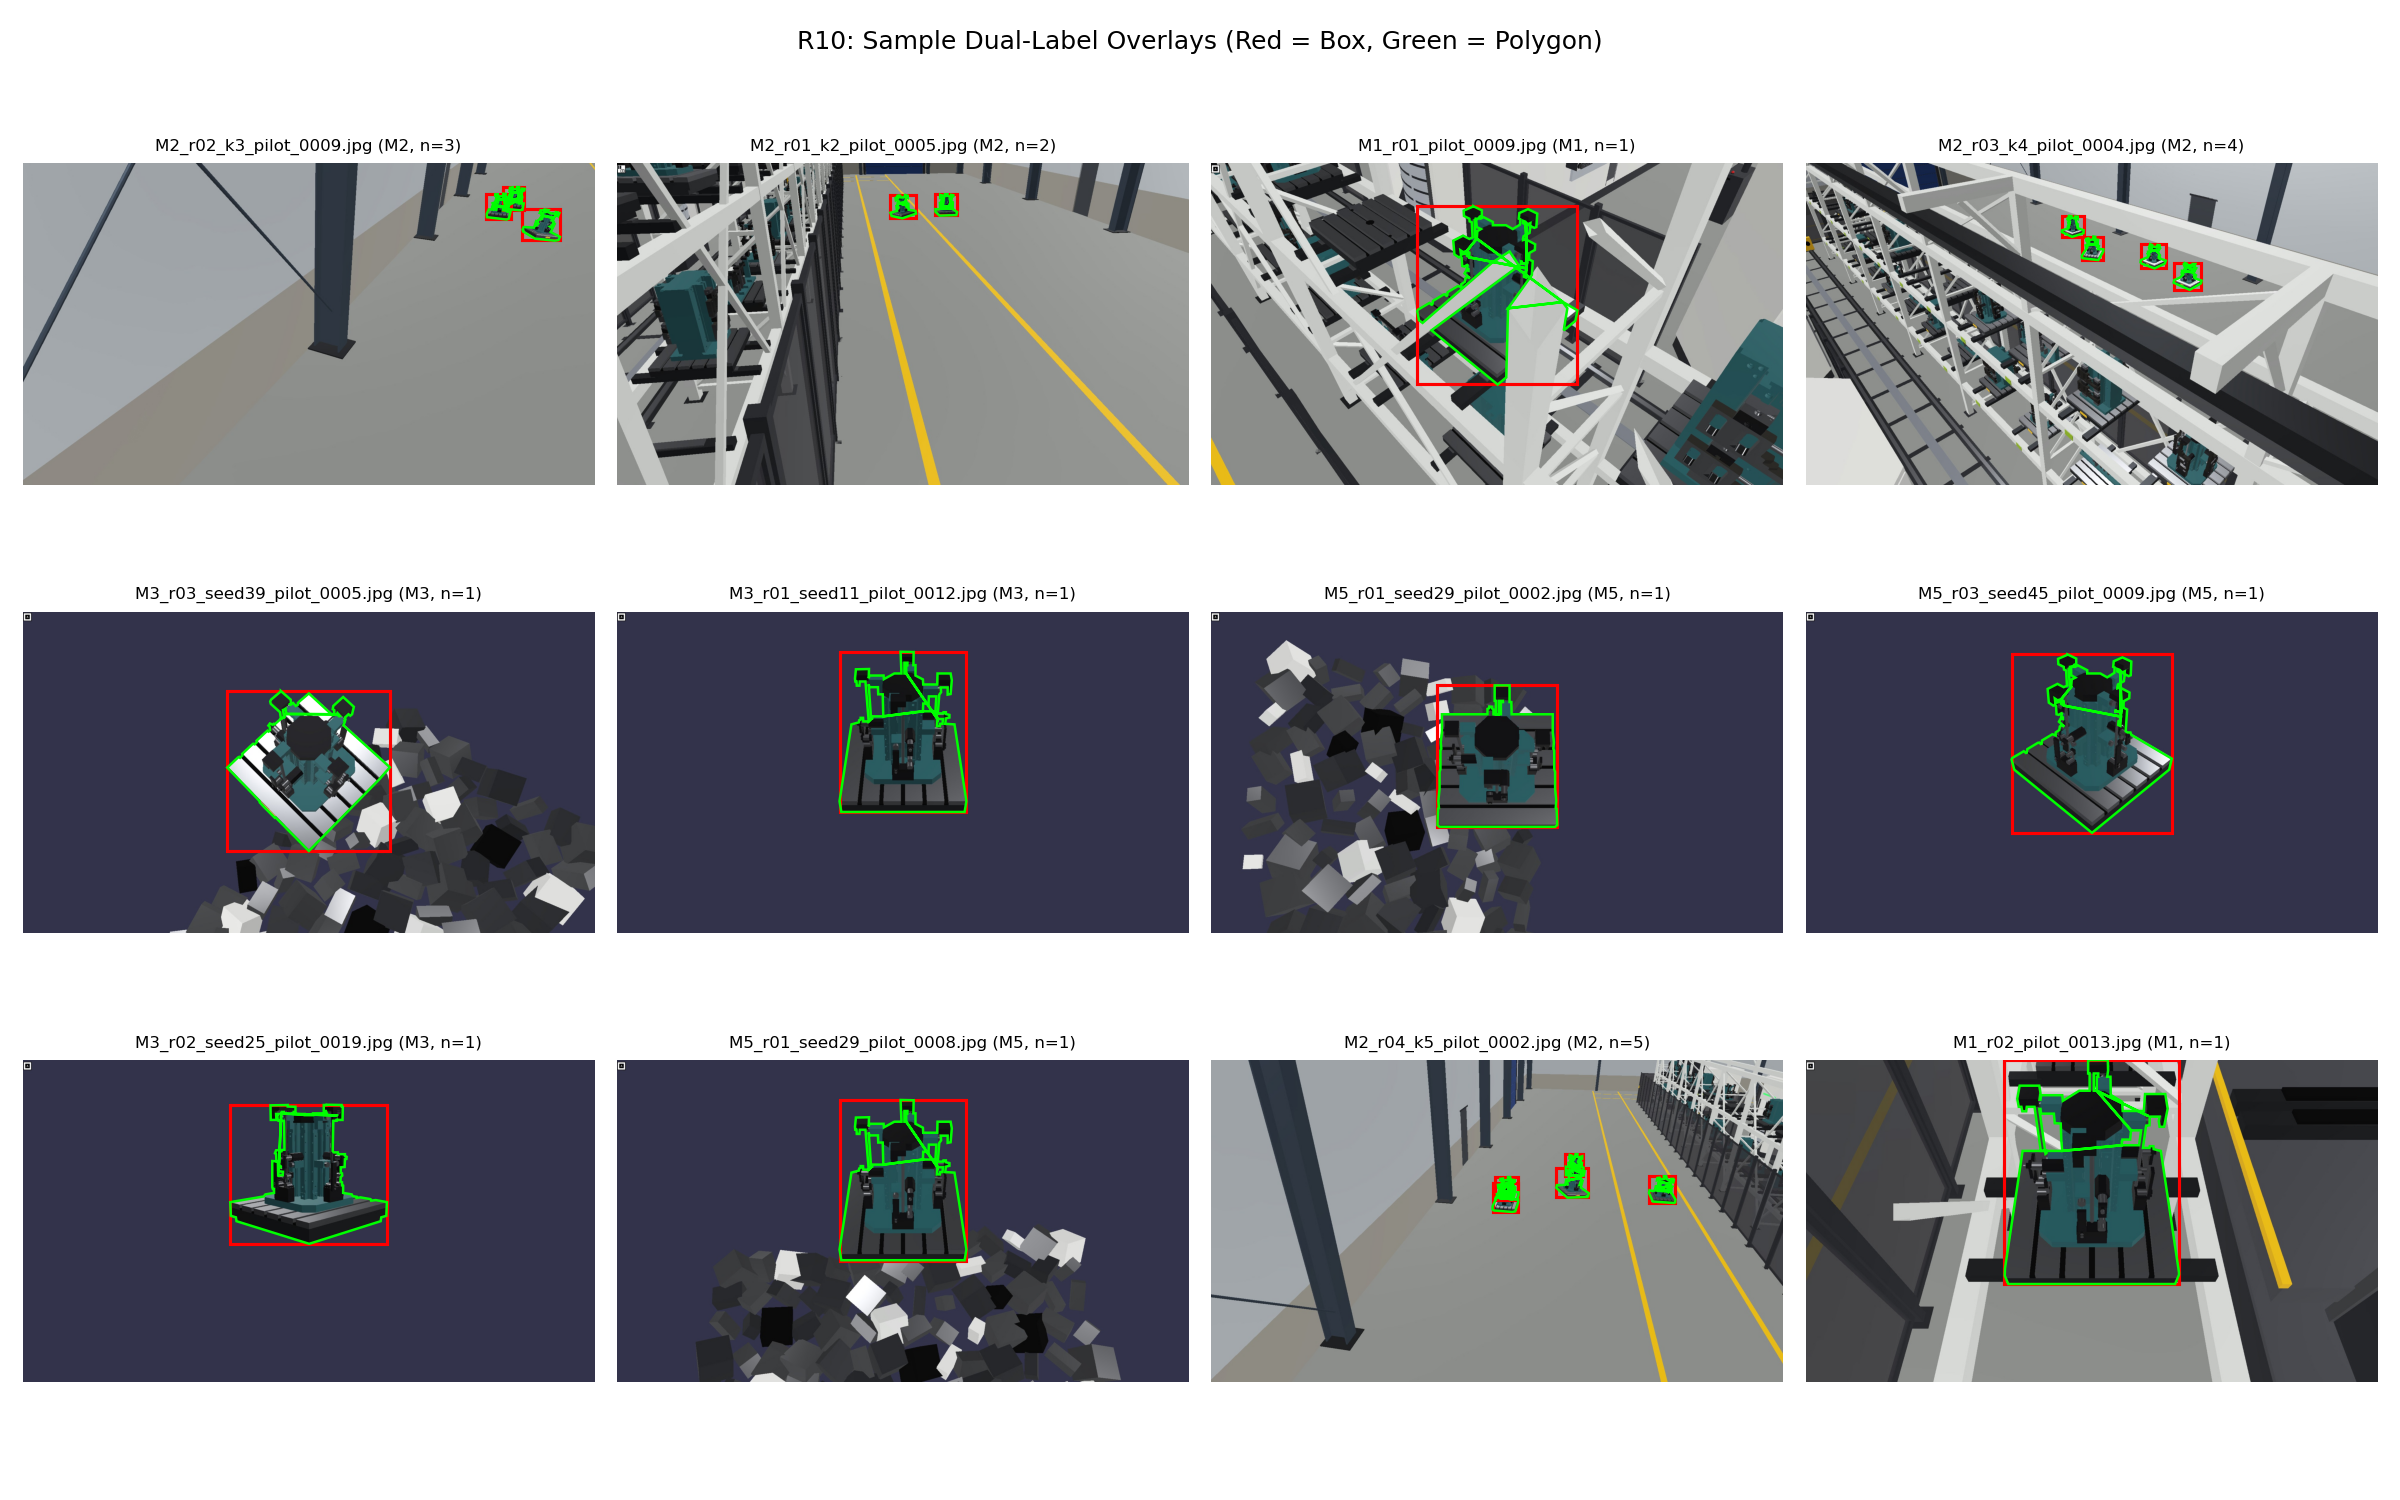

In [18]:
# ==================== CELL 12: R10 - Label Quality & Visual Overlays ====================
max_poly_err = float(max(poly_box_diffs_px)) if poly_box_diffs_px else 0.0
mean_poly_err = float(np.mean(poly_box_diffs_px)) if poly_box_diffs_px else 0.0
r10_pass = (len(r10_errors) == 0) and (max_poly_err <= 2.0)

# Generate a 3x4 grid of sample label overlays (red boxes + green segmentation polygons)
sample_df = manifest.sample(n=min(12, len(manifest)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, (_, row) in enumerate(sample_df.iterrows()):
    ax = axes[idx]
    img_name = row["image"]
    stem = os.path.splitext(img_name)[0]
    im = Image.open(os.path.join(DATASET_DIR, "images", img_name))
    w_px, h_px = im.size
    ax.imshow(im)

    with open(os.path.join(DATASET_DIR, "labels", f"{stem}.txt"), "r") as fb:
        for line in fb:
            parts = list(map(float, line.strip().split()))
            _, cx, cy, bw, bh = parts
            x1, y1 = (cx - bw / 2.0) * w_px, (cy - bh / 2.0) * h_px
            rect = patches.Rectangle((x1, y1), bw * w_px, bh * h_px,
                                     linewidth=1.5, edgecolor="red", facecolor="none")
            ax.add_patch(rect)

    with open(os.path.join(DATASET_DIR, "labels_seg", f"{stem}.txt"), "r") as fs:
        for line in fs:
            parts = list(map(float, line.strip().split()))
            pts = np.array(parts[1:], dtype=float).reshape(-1, 2)
            pts[:, 0] *= w_px
            pts[:, 1] *= h_px
            poly = patches.Polygon(pts, closed=True, linewidth=1.2, edgecolor="lime", facecolor="none")
            ax.add_patch(poly)

    ax.set_title(f"{img_name} ({row['mode']}, n={row['n_instances']})", fontsize=8)
    ax.axis("off")

for idx in range(len(sample_df), 12):
    axes[idx].axis("off")

plt.suptitle("R10: Sample Dual-Label Overlays (Red = Box, Green = Polygon)", fontsize=12)
plt.tight_layout()
out_r10 = f"{FIG_DIR}/R10_label_overlays.png"
plt.savefig(out_r10, dpi=150)
plt.close()

print("=== R10: Label Quality and Box–Polygon Consistency ===")
print("Target   : 0 format errors; polygon extent within 2.0 px of bounding box")
print(f"Measured : {len(r10_errors)} format errors; max extent diff = {max_poly_err:.2f} px (mean = {mean_poly_err:.2f} px)")
if r10_errors:
    print("Sample errors:", r10_errors[:5])
print(f"Status   : {'PASS' if r10_pass else 'FAIL'}")
display(IPyImage(filename=out_r10))

=== R11: Near-Duplicate Rate ===
Method   : 64-bit Perceptual Hashing (imagehash.phash), Hamming distance <= 5
Target   : <= 2.0% of images
Measured : 165 / 258 images (63.95%)

Near-duplicate breakdown by mode:
      Total  Near_Duplicates
mode                        
M1       40                4
M2       52                2
M3       60               56
M4       51               51
M5       55               52

Status   : FAIL


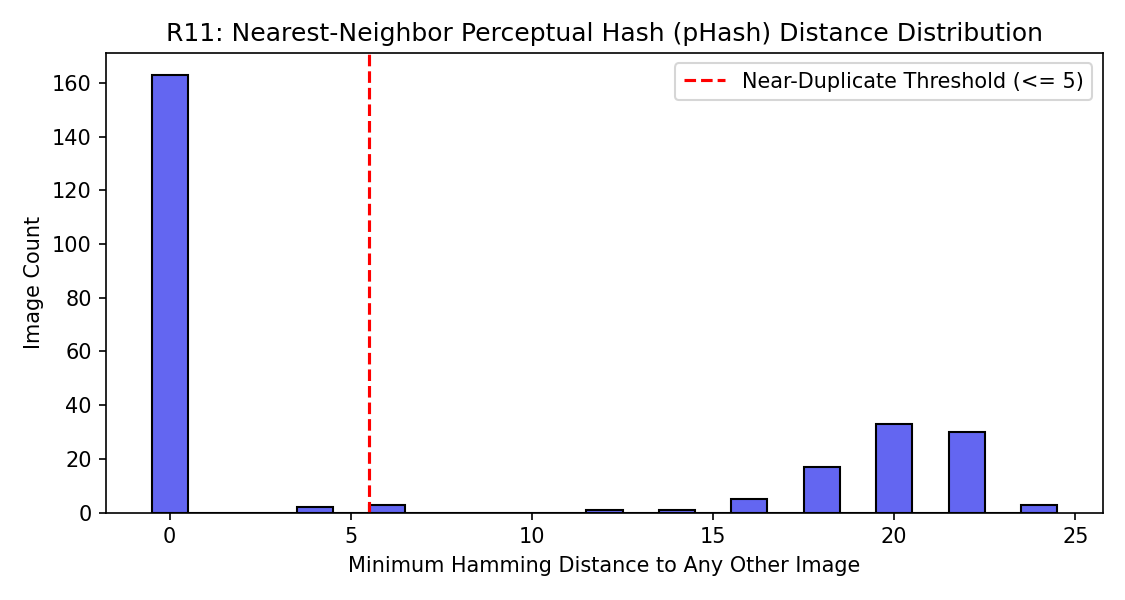

In [19]:
# ==================== CELL 13: R11 - Near-Duplicate Rate (pHash) ====================
img_files = [os.path.join(DATASET_DIR, "images", name) for name in manifest["image"]]
hashes = [imagehash.phash(Image.open(p)) for p in img_files]

PHASH_THRESH = 5
dup_idx = set()
min_dists = []

for i in range(len(hashes)):
    dists_i = [hashes[i] - hashes[j] for j in range(len(hashes)) if i != j]
    min_dists.append(min(dists_i))
    for j in range(i + 1, len(hashes)):
        if hashes[i] - hashes[j] <= PHASH_THRESH:
            dup_idx.add(i)
            dup_idx.add(j)

dup_rate = len(dup_idx) / len(hashes) * 100.0
r11_pass = dup_rate <= 2.0
manifest["is_near_dup"] = [i in dup_idx for i in range(len(hashes))]

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.hist(min_dists, bins=range(0, max(min_dists) + 2), color="#6366F1", edgecolor="black", align="left")
ax.axvline(PHASH_THRESH + 0.5, color="red", linestyle="--", label=f"Near-Duplicate Threshold (<= {PHASH_THRESH})")
ax.set_title("R11: Nearest-Neighbor Perceptual Hash (pHash) Distance Distribution")
ax.set_xlabel("Minimum Hamming Distance to Any Other Image")
ax.set_ylabel("Image Count")
ax.legend()

plt.tight_layout()
out_r11 = f"{FIG_DIR}/R11_phash_distribution.png"
plt.savefig(out_r11, dpi=150)
plt.close()

print("=== R11: Near-Duplicate Rate ===")
print(f"Method   : 64-bit Perceptual Hashing (imagehash.phash), Hamming distance <= {PHASH_THRESH}")
print(f"Target   : <= 2.0% of images")
print(f"Measured : {len(dup_idx)} / {len(hashes)} images ({dup_rate:.2f}%)")
print("\nNear-duplicate breakdown by mode:")
print(manifest.groupby("mode")["is_near_dup"].agg(Total="count", Near_Duplicates="sum"))
print(f"\nStatus   : {'PASS' if r11_pass else 'FAIL'}")
display(IPyImage(filename=out_r11))

In [20]:
# ==================== CELL 14: Master R1-R11 Verification Summary Table ====================
summary_df = pd.DataFrame([
    ["R1", "Dataset size & class", "1,000 images, 1 class", f"{total_images} images, {class_names}", "PASS" if r1_pass else "FAIL"],
    ["R2", "Instances per image", "70/10/8/6/6% (±3%)", "/".join(f"{v:.1f}%" for v in inst_shares), "PASS" if r2_pass else "FAIL"],
    ["R3", "Image format", "1 resolution, non-square", f"{res_list[0][0]}x{res_list[0][1]} ({len(res_list)} res)" if res_list else "None", "PASS" if r3_pass else "FAIL"],
    ["R4", "Generation-mode mix", "M2: 300–330; Auto >=10%", ", ".join(f"{m}:{mode_counts[m]}" for m in modes_order), "PASS" if r4_pass else "FAIL"],
    ["R5", "Scale ladder", "30/40/30% (±5%)", f"{r5_meas[0]:.1f}/{r5_meas[1]:.1f}/{r5_meas[2]:.1f}%", "PASS" if r5_pass else "FAIL"],
    ["R6", "Viewpoint coverage", "24/24 cells covered", f"{covered_cells}/24 cells", "PASS" if r6_pass else "FAIL"],
    ["R7", "Position in frame", "Outer >=3%, Centre <=50%", f"MinOuter={min_outer_pct:.1f}%, Centre={centre_pct:.1f}%", "PASS" if r7_pass else "FAIL"],
    ["R8", "Truncation share", "5.0–15.0% of instances", f"{trunc_rate:.2f}%", "PASS" if r8_pass else "FAIL"],
    ["R9", "Minimum box size", ">= 16.0 px short side", f"{min_short_px:.2f} px", "PASS" if r9_pass else "FAIL"],
    ["R10", "Label quality", "0 errors, diff <= 2.0 px", f"{len(r10_errors)} errors, max diff={max_poly_err:.2f} px", "PASS" if r10_pass else "FAIL"],
    ["R11", "Near-duplicate rate", "<= 2.0% (pHash <= 5)", f"{dup_rate:.2f}%", "PASS" if r11_pass else "FAIL"],
], columns=["Req", "Requirement", "Target", "Measured", "Status"])

summary_df.to_csv(os.path.join(FIG_DIR, "summary_table.csv"), index=False)
display(summary_df)

,Req,Requirement,Target,Measured,Status
0,R1,Dataset size & class,"1,000 images, 1 class","258 images, {0: 'pallet_part00_phase20'}",FAIL
1,R2,Instances per image,70/10/8/6/6% (±3%),79.8%/7.4%/3.9%/5.0%/3.9%,FAIL
2,R3,Image format,"1 resolution, non-square",1920x1080 (1 res),PASS
3,R4,Generation-mode mix,M2: 300–330; Auto >=10%,"M1:40, M2:52, M3:60, M4:51, M5:55",FAIL
4,R5,Scale ladder,30/40/30% (±5%),42.6/17.8/39.6%,FAIL
5,R6,Viewpoint coverage,24/24 cells covered,24/24 cells,PASS
6,R7,Position in frame,"Outer >=3%, Centre <=50%","MinOuter=2.1%, Centre=62.2%",FAIL
7,R8,Truncation share,5.0–15.0% of instances,4.79%,FAIL
8,R9,Minimum box size,>= 16.0 px short side,42.00 px,PASS
9,R10,Label quality,"0 errors, diff <= 2.0 px","0 errors, max diff=8.00 px",FAIL
